## Lab 3 - Millions of TVs, Who Is Watching?

Name: Korinnyi Zakhar
Group: KM-43

## Setup

In [38]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


## Task 1.1 — Five questions
**Answer:**

| | `acr_sessions` (smart-TV ACR) | Lab 1 `viewings` (panel) |
|---|---|---|
| **Grain** | One session of one thing on one TV | One viewing event of one respondent (H, R, L, S) on one network |
| **Key** | `tv_id` (device); `hashed_ip` (weak household link) | `respondent_id` + `resp_type`; joins to weights by id + date |
| **Coverage** | 29,940 opted-in connected TVs; one TV per home; any network, apps, unknown | ~4,254 homes, 10,210 persons; all TVs in the home; ten networks, in-tab days |
| **Weight** | None: each TV counts once | Daily weights; projects to 125.8M homes, 317.3M persons |
| **Provenance** | Vendor ACR feed under opt-in; synthetic; household file compiled/modeled | Purpose-built representative panel; synthetic, calibrated to published audiences |

**Biggest difference: weight.** The panel is representative by design and is projected with weights, so a row becomes a population. The ACR feed is a large, self-selected convenience sample with no weights: every TV counts once, so its numbers describe the footprint, not the US. Coverage (who is in the file) and key (devices vs. people) are the reasons it needs weights, but the missing weight is what makes the numbers non-comparable out of the box.

### Task 1.2 - Size and shape

In [39]:
# Convert start_utc and end_utc to US Eastern
acr_sessions['start_utc'] = pd.to_datetime(acr_sessions['start_utc'])
acr_sessions['end_utc'] = pd.to_datetime(acr_sessions['end_utc'])

acr_sessions['start_et'] = acr_sessions['start_utc'].dt.tz_convert('US/Eastern')
acr_sessions['end_et'] = acr_sessions['end_utc'].dt.tz_convert('US/Eastern')

# Broadcast days run 06:00–05:59 Eastern
acr_sessions['broadcast_day'] = (acr_sessions['start_et'] - pd.Timedelta(hours=6)).dt.date
acr_sessions['duration_sec'] = (acr_sessions['end_et'] - acr_sessions['start_et']).dt.total_seconds()
acr_sessions['duration_hrs'] = acr_sessions['duration_sec'] / 3600

# Total TVs, sessions, and broadcast days
total_tvs = acr_sessions['tv_id'].nunique()
total_sessions = len(acr_sessions)
broadcast_days = acr_sessions['broadcast_day'].nunique()

# Drop every session shorter than 1 minute
acr_sessions_edited = acr_sessions[acr_sessions['duration_sec'] >= 60].copy()

# In-tab TVs
in_tab_tv_days = acr_sessions_edited.groupby(['broadcast_day', 'tv_id']).size().reset_index()
avg_tvs_in_tab = in_tab_tv_days.groupby('broadcast_day')['tv_id'].nunique().mean()

# Hours per in-tab TV per day
total_in_tab_tv_days = len(in_tab_tv_days)
hrs_before = acr_sessions['duration_hrs'].sum() / total_in_tab_tv_days
hrs_after = acr_sessions_edited['duration_hrs'].sum() / total_in_tab_tv_days

# Share of sessions dropped
share_dropped = (total_sessions - len(acr_sessions_edited)) / total_sessions * 100

print("TVs:", total_tvs)
print("Sessions:", total_sessions)
print("Broadcast days:", broadcast_days)
print("Average TVs in-tab per day:", round(avg_tvs_in_tab, 1))
print("Hours per TV per day, raw:", f"{hrs_before:.2f}")
print("Hours per TV per day, after edit rule:", f"{hrs_after:.2f}")
print("Share of sessions dropped:", f"{share_dropped / 100:.3f}")

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074.1
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.70
Share of sessions dropped: 0.299


### Task 1.3 - What the TV could not see


In [40]:
# Total hours after edit rule
total_hours_edited = acr_sessions_edited['duration_hrs'].sum()

# table: share of hours by session_type and by input_source
session_type_share = (acr_sessions_edited.groupby('session_type')['duration_hrs'].sum() / total_hours_edited).round(3).reset_index(name='share')
display(session_type_share)

input_source_share = (acr_sessions_edited.groupby('input_source')['duration_hrs'].sum() / total_hours_edited).round(3).reset_index(name='share')
display(input_source_share)

# Calculate % of unknown TV-on hours
unknown_share = (acr_sessions_edited[acr_sessions_edited['session_type'] == 'unknown']['duration_hrs'].sum() / total_hours_edited * 100)
print(f"Share of TV-on hours unknown (%): {unknown_share:.1f}")

,session_type,share
0,app,0.257
1,dvr,0.025
2,live,0.322
3,unknown,0.396


,input_source,share
0,antenna,0.086
1,built_in_app,0.307
2,cable_box,0.276
3,game_or_disc,0.024
4,satellite_box,0.076
5,streaming_device,0.231


Share of TV-on hours unknown (%): 39.6


**Answer:** The actual ACR stream may have even more unidentified views than this one, since the match depends on the reference image library, and the library never covers everything. This requires that every live broadcast, local station, and ad creative be tracked and imported, and any missing gaps result in “TV on, nothing recognized.” Live streams also introduce losses due to scrolling (weak matches that are discarded) and apps that block ACR. Two types of views that become “unknown” as a result: 1. Content not included in the library, such as local TV channels or channels that the provider doesn’t track, as well as streaming content or content from apps provided by services that don’t support ACR or lack reference patterns. 2. Screen usage outside of television broadcasts, for which there is nothing to compare the data against—for example, a game console, DVD/Blu-ray player, computer screen, home video, or screen mirroring. Time-delayed playback from a DVR and sessions with playback control functions (pause, rewind, skip) may also fail to produce a clear match.

### Task 2.1 - Match

In [41]:
# Get unique IPs for each TV
tv_ip = acr_sessions[['tv_id', 'hashed_ip']].drop_duplicates()
tv_ip = tv_ip.drop_duplicates('tv_id').copy()

# Count households behind each IP
hh_per_ip = hh_attributes.groupby('hashed_ip')['household_id'].nunique()
tv_ip['n_hh'] = tv_ip['hashed_ip'].map(hh_per_ip).fillna(0).astype(int)

n_tvs = len(tv_ip)
print("Matched to one household (%):", f"{(tv_ip['n_hh'] == 1).sum() / n_tvs * 100:.1f}")
print("Shared IP, unresolved (%):", f"{(tv_ip['n_hh'] > 1).sum() / n_tvs * 100:.1f}")
print("Not matched (%):", f"{(tv_ip['n_hh'] == 0).sum() / n_tvs * 100:.1f}")

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


**Answer:** An IP address identifies a network connection, not a household or an individual, so it is a weak identifier. It can be shared, for example, in apartment buildings or when using shared routers, multiple households may be located at a single address, so some TVs correspond to multiple households and cannot be identified. It is unstable because households’ IP addresses change; therefore, the address displayed in the TV stream and the one contained in the consumer file may differ, leaving TVs unidentified. A match is not the same as a correct match, because an incorrect match based on an IP address associates attributes with a different household, and any audience or weighting built on that basis inherits this error (correct share = match rate × accuracy). A study by CIMM and Truthset (2025) found that the links between IP addresses and mailing addresses are accurate on average in only about 13% of cases.

### Task 2.2 - Profile

In [42]:
# Date range and income mapping
d_start, d_end = pd.Timestamp('2024-10-14').date(), pd.Timestamp('2024-10-27').date()
inc_group = {'Under $25k': 'Under $50k', '$25k-$50k': 'Under $50k',
             '$50k-$75k': '$50-100k', '$75k-$100k': '$50-100k',
             '$100k-$150k': '$100k+', '$150k+': '$100k+'}

# Footprint profile (matched TVs only)
matched = tv_ip[tv_ip['n_hh'] == 1].merge(
    hh_attributes.drop_duplicates('hashed_ip')[['hashed_ip', 'region', 'income_band']],
    on='hashed_ip', how='left')
matched['income_group'] = matched['income_band'].map(inc_group)

# Panel average weights for in-tab days
panel_hh = daily_weights[daily_weights['resp_type'] == 'H'].copy()
panel_hh['bday'] = pd.to_datetime(panel_hh['broadcast_date']).dt.date
panel_hh = panel_hh[(panel_hh['bday'] >= d_start) & (panel_hh['bday'] <= d_end)]
hh_w = panel_hh.groupby('respondent_id')['weight'].mean().rename('w').reset_index()

# Map and merge panel attributes (region & income)
attr_names = attributes.set_index('attr_id')['attr_name']
va = viewer_attributes[viewer_attributes['attr_id'].isin(list(range(811, 817)) + list(range(841, 845)))].copy()
va = va[pd.to_numeric(va['value'], errors='coerce').fillna(1) != 0]
va['name'] = va['attr_id'].map(attr_names)
reg = va[va['attr_id'].between(841, 844)][['respondent_id', 'name']].rename(columns={'name': 'region'})
inc = va[va['attr_id'].between(811, 816)][['respondent_id', 'name']].rename(columns={'name': 'income_band'})
inc['income_group'] = inc['income_band'].map(inc_group)
panel_prof = (hh_w.merge(reg.drop_duplicates('respondent_id'), on='respondent_id', how='left')
                  .merge(inc.drop_duplicates('respondent_id')[['respondent_id', 'income_group']],
                         on='respondent_id', how='left'))

# table: group, footprint share, panel share, index (region and income)
def profile_table(col, order):
    fp = matched.dropna(subset=[col])[col].value_counts(normalize=True)
    pn_df = panel_prof.dropna(subset=[col])
    pn = pn_df.groupby(col)['w'].sum() / pn_df['w'].sum()
    t = pd.DataFrame({'footprint share': fp, 'panel share': pn}).reindex(order)
    t['index'] = t['footprint share'] / t['panel share'] * 100
    t.insert(0, 'dimension', col)
    t.index.name = 'group'
    return t

profile = pd.concat([
    profile_table('region', ['Northeast', 'Midwest', 'South', 'West']),
    profile_table('income_group', ['Under $50k', '$50-100k', '$100k+'])])
print(profile.to_string(formatters={'footprint share': '{:.3f}'.format,
                                    'panel share': '{:.3f}'.format, 'index': '{:.1f}'.format}))

               dimension footprint share panel share index
group                                                     
Northeast         region           0.150       0.170  88.0
Midwest           region           0.201       0.210  96.0
South             region           0.383       0.379 101.0
West              region           0.266       0.241 110.4
Under $50k  income_group           0.259       0.361  71.8
$50-100k    income_group           0.320       0.289 110.8
$100k+      income_group           0.421       0.350 120.1


**Answer:**
The following are overrepresented in the coverage area: households with an income of more than 100,000 (index 120.1), households with an income of 50,000–100,000 (110.8), and the West (110.4). Underrepresented are: households with incomes below 50,000 (index 71.8) and the Northeast (88.0). The Midwest (96.0) and the South (101.0) are close to the sample, so the discrepancy in income is most pronounced: the coverage area has approximately 28% fewer low-income households than the sample and approximately 20% more high-income households. One reason is that smart-TV coverage, based on voluntary consent, reflects who owns and connects newer smart TVs; households with higher incomes are more likely to replace their TVs, use the Internet more frequently, and agree to setup prompts. The second reason, related to the data, lies in the matching stage, where households in apartment buildings share an IP address and are excluded as unidentifiable (11.8% of TVs), and these households tend to have lower incomes, so the matched coverage area is further skewed toward higher-income groups.

### Task 2.3 Ratings

In [43]:
# Helper to convert timestamps
def to_naive_et(series):
    s_ = pd.to_datetime(series)
    if s_.dt.tz is not None:
        s_ = s_.dt.tz_convert('US/Eastern').dt.tz_localize(None)
    return s_

acr_sessions_edited['start_local'] = acr_sessions_edited['start_et'].dt.tz_localize(None)
acr_sessions_edited['end_local'] = acr_sessions_edited['end_et'].dt.tz_localize(None)

live_sessions = acr_sessions_edited[acr_sessions_edited['session_type'] == 'live']
tvs_in_tab_by_day = acr_sessions_edited.groupby('broadcast_day')['tv_id'].nunique()

# Prepare telecast reference data
tc = reference_ratings.merge(
    programs[['telecast_id', 'network_code', 'program_name', 'start_ts', 'end_ts', 'broadcast_date']],
    on='telecast_id', how='left')
tc['start_local'] = to_naive_et(tc['start_ts'])
tc['end_local'] = to_naive_et(tc['end_ts'])
tc['bday'] = pd.to_datetime(tc['broadcast_date']).dt.date

# Calculate unweighted TV rating for each telecast
rows = []
for _, r in tc.iterrows():
    sess = live_sessions[live_sessions['network_code'] == r['network_code']]
    overlap_sec = (sess['end_local'].clip(upper=r['end_local'])
                   - sess['start_local'].clip(lower=r['start_local'])).dt.total_seconds()
    watched = sess.loc[overlap_sec >= 60, 'tv_id'].nunique()
    base = tvs_in_tab_by_day[r['bday']]
    rows.append({'telecast_id': r['telecast_id'], 'program': r['program_name'], 'network': r['network_code'],
                 'date': r['bday'], 'tvs_watched': watched, 'tvs_in_tab': base,
                 'tv_rating': watched / base * 100, 'reference': r['hh_rating']})

# table: telecast, TVs' HH rating, reference HH rating
tv_ratings = pd.DataFrame(rows)
tv_ratings['ratio'] = tv_ratings['tv_rating'] / tv_ratings['reference']
print(tv_ratings.to_string(index=False, formatters={
    'tv_rating': '{:.1f}'.format, 'reference': '{:.1f}'.format, 'ratio': '{:.2f}'.format}))

 telecast_id                              program network       date  tvs_watched  tvs_in_tab tv_rating reference ratio
     1013636                       MLB Postseason     FOX 2024-10-25         4947       29940      16.5      25.9  0.64
     1021823                         NFL Football     NBC 2024-10-27         6362       29940      21.2      33.1  0.64
     1004042                                 NCIS     CBS 2024-10-14         1608       29940       5.4      10.6  0.51
     1012442                              Hannity     FNC 2024-10-16          247       29940       0.8       2.3  0.36
     1016852                    Unsellable Houses    HGTV 2024-10-16          628       29940       2.1       3.7  0.57
     1013031        Halloween Baking Championship    FOOD 2024-10-14          295       29940       1.0       1.6  0.60
     1014236                         Grotesquerie      FX 2024-10-16          677       29940       2.3       3.5  0.64
     1003476 The Real Housewives of New 

**Answer:** Household TV viewership ratings are too low for all programs, as they range from only 36% to 64% of the benchmark value. The three programs closest to the benchmark are 0.64 (“World Series,” “Sunday Night Football,” and “Grotesquerie”), while the furthest are “Hannity” (0.36) and “NCIS” (0.51); the rest fall within the range of 0.57–0.60. Two factors reduce each rating by approximately the same amount: the system records only one TV per household (out of approximately 2.6 TVs) participating in the survey, and a significant portion of viewing is recorded as unknown (39.6% of TV viewing hours), which is never counted as viewing of a specific channel. Since these effects are common to all television programs, differences among them indicate who is included in the coverage area. The lowest figures are for “Hannity” (Fox News) and “NCIS” (CBS), whose audiences consist of older viewers, while FX and Bravo, which target younger audiences, remain at or near the overall level. This aligns with the coverage gap, in which certain households are underrepresented—particularly low-income households (index of 71.8 for incomes below $50,000), which typically include many older adults.

## Task 3.1 — Hours per home

In [44]:
LIVE_VALUE = 'Live'   # value of viewings for live viewing
ten_networks = programs['network_code'].unique()
d_start, d_end = pd.Timestamp('2024-10-14').date(), pd.Timestamp('2024-10-27').date()

# Filter live viewing for the 10 networks on TVs
tv_live_ten = acr_sessions_edited[(acr_sessions_edited['session_type'] == 'live')
                                  & (acr_sessions_edited['network_code'].isin(ten_networks))]
tv_live_hrs = tv_live_ten['duration_hrs'].sum() / total_in_tab_tv_days

# Filter panel households (H rows) for the same networks and dates
panel_h = viewings[(viewings['resp_type'] == 'H') & (viewings['network_code'].isin(ten_networks))].copy()
panel_h['start_local'] = to_naive_et(panel_h['start_ts'])
panel_h['end_local'] = to_naive_et(panel_h['end_ts'])
panel_h['bday'] = (panel_h['start_local'] - pd.Timedelta(hours=6)).dt.date
panel_h['hrs'] = (panel_h['end_local'] - panel_h['start_local']).dt.total_seconds() / 3600
panel_h = panel_h[(panel_h['bday'] >= d_start) & (panel_h['bday'] <= d_end)]
if 'playback' in panel_h.columns:
    panel_h = panel_h[panel_h['playback'] == LIVE_VALUE]

# Apply daily weights to the panel
w_h = daily_weights[daily_weights['resp_type'] == 'H'].copy()
w_h['bday'] = pd.to_datetime(w_h['broadcast_date']).dt.date
w_h = w_h[(w_h['bday'] >= d_start) & (w_h['bday'] <= d_end)]
panel_h = panel_h.merge(w_h[['respondent_id', 'bday', 'weight']].rename(columns={'weight': 'w_day'}),
                        on=['respondent_id', 'bday'], how='inner')

# Calculate weighted live hours for panel
panel_live_hrs = (panel_h['hrs'] * panel_h['w_day']).sum() / w_h['weight'].sum()

print("Live hours per TV per day (ten networks):", f"{tv_live_hrs:.2f}")
print("Live hours per panel household per day (ten networks):", f"{panel_live_hrs:.2f}")

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92


**Answer:** The smart-TV data is lower: 0.87 live hours per TV per day against 1.92 per panel household, a gap of 1.05 hours, so one TV shows only about 45% of what an average panel household watches. The main reason is the unit. A panel household record covers viewing on every set in the home, while a TV in the feed is one set, and the ACR provider sees only about 1.1 of the roughly 2.6 sets in a home (the same brand). The ratio 1.1 / 2.6 is about 0.42, close to the observed 0.45. In addition, the feed logs unrecognized viewing as unknown, which never counts as live viewing of a network, and DVR and app sessions are not live, while the panel rows are live viewing only.

## Task 3.2 — Network shares

In [45]:
# Calculate network shares for TVs vs Panel
tv_net = tv_live_ten.groupby('network_code')['duration_hrs'].sum()
panel_net = (panel_h['hrs'] * panel_h['w_day']).groupby(panel_h['network_code']).sum()

# table: network, share in TVs, share in panel
net_table = pd.DataFrame({'share in TVs': tv_net / tv_net.sum(),
                          'share in panel': panel_net / panel_net.sum()}).fillna(0)
net_table['diff (TVs - panel)'] = net_table['share in TVs'] - net_table['share in panel']
net_table.index.name = 'network'
net_table = net_table.sort_values('share in panel', ascending=False)
print(net_table.to_string(float_format=lambda x: f"{x:.3f}"))

         share in TVs  share in panel  diff (TVs - panel)
network                                                  
NBC             0.214           0.206               0.007
CBS             0.182           0.196              -0.014
FOX             0.201           0.194               0.008
ABC             0.196           0.187               0.009
FNC             0.085           0.110              -0.025
HGTV            0.034           0.031               0.003
FOOD            0.024           0.022               0.002
FX              0.028           0.022               0.006
HIST            0.019           0.019               0.001
BRAVO           0.016           0.013               0.003


## Task 3.3 — What each can see
**Answer:** (Network shares, Task 3.2.) The shares are close, but the smart-TV data under-states FNC by 2.5 points (0.085 against 0.110) and CBS by 1.4 points (0.182 against 0.196). It over-states the other broadcast networks, ABC, FOX and NBC, by 0.7 to 0.9 points, and the small cable networks FX, BRAVO and HGTV slightly. FNC and CBS are the networks with older audiences, which fits a footprint with too few older homes.

The panel can see what the smart-TV data cannot: people, meaning who is watching, with age and sex, co-viewing and guests, while ACR sees only TV sets; every TV in the home regardless of brand or connection, including antenna-only and unconnected sets, and homes that never opted in, whereas ACR sees about one of the roughly 2.6 sets per home; a representative, weighted sample of US homes, so its numbers project to the universe without correction. The smart-TV data can see what the panel's ten-network files can't: viewing on any US network beyond the ten, plus apps, DVR playback and unrecognized "TV on" time, with the input source (cable box, antenna, streaming device, game or disc); very large volume at second-level precision, so small networks, narrow time windows and local market have far more observations than the panel can give; a link to household attributes through the hashed IP, which allows audience profiling without a survey.

## Task 4.1 — Daily plots

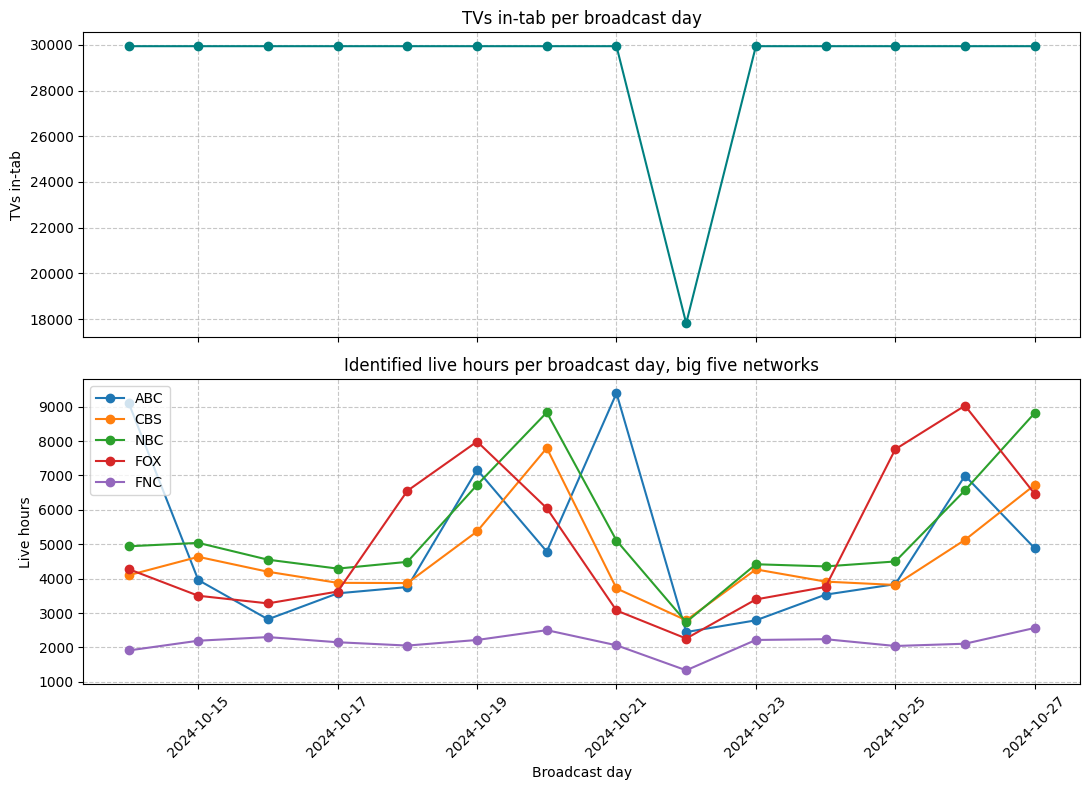

In [46]:
big_five = ['ABC', 'CBS', 'NBC', 'FOX', 'FNC']

# TVs in-tab per broadcast day
intab_daily = acr_sessions_edited.groupby('broadcast_day')['tv_id'].nunique()

# Live hours per day for the big five networks
live_big = acr_sessions_edited[(acr_sessions_edited['session_type'] == 'live')
                               & (acr_sessions_edited['network_code'].isin(big_five))]
live_hours_daily = (live_big.groupby(['broadcast_day', 'network_code'])['duration_hrs'].sum()
                    .unstack('network_code').reindex(columns=big_five))

# plot: TVs in-tab per day; live hours per day for the big five networks
intab_plot = intab_daily.copy()
intab_plot.index = pd.to_datetime(intab_plot.index)
live_plot = live_hours_daily.copy()
live_plot.index = pd.to_datetime(live_plot.index)

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
axes[0].plot(intab_plot.index, intab_plot.values, marker='o', color='teal')
axes[0].set_title('TVs in-tab per broadcast day')
axes[0].set_ylabel('TVs in-tab')
axes[0].grid(True, linestyle='--', alpha=0.7)

for net in big_five:
    axes[1].plot(live_plot.index, live_plot[net], marker='o', label=net)
axes[1].set_title('Identified live hours per broadcast day, big five networks')
axes[1].set_ylabel('Live hours')
axes[1].set_xlabel('Broadcast day')
axes[1].grid(True, linestyle='--', alpha=0.7)
axes[1].legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Task 4.2 — Spike and broken day

In [47]:
# Find the biggest spike (date and network with max live hours)
live_all = acr_sessions_edited[acr_sessions_edited['session_type'] == 'live']
live_by_day_net = live_all.groupby(['broadcast_day', 'network_code'])['duration_hrs'].sum()
spike_day, spike_net = live_by_day_net.idxmax()

# Check what aired during the spike
aired = programs[(programs['network_code'] == spike_net)
                 & (pd.to_datetime(programs['broadcast_date']).dt.date == spike_day)]

# Daily diagnostics: in-tab TVs, sessions, and unknown share
daily = pd.DataFrame({'tvs_in_tab': intab_daily,
                      'sessions': acr_sessions_edited.groupby('broadcast_day').size(),
                      'session_hours': acr_sessions_edited.groupby('broadcast_day')['duration_hrs'].sum()})
daily['hours_per_tv'] = daily['session_hours'] / daily['tvs_in_tab']
unk_hrs = (acr_sessions_edited[acr_sessions_edited['session_type'] == 'unknown']
           .groupby('broadcast_day')['duration_hrs'].sum())
daily['unknown_share'] = unk_hrs / daily['session_hours']
daily['weekday'] = pd.to_datetime(daily.index).day_name()

# Broken day: day with in-tab denominator furthest from the median
broken_day = (daily['tvs_in_tab'] / daily['tvs_in_tab'].median() - 1).abs().idxmax()

print("Biggest spike (date, network):", spike_day, spike_net)
print("Broken day (date):", broken_day)

print(aired[aired['program_name'] == 'NFL Football'][['program_name', 'start_ts', 'end_ts']].to_string(index=False))
cols = ['tvs_in_tab', 'sessions', 'session_hours', 'hours_per_tv', 'unknown_share']
normal = daily.drop(broken_day)
normal = normal[normal['weekday'].isin(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'])]
compare = pd.DataFrame({'broken day': daily.loc[broken_day, cols].astype(float),
                        'median of other weekdays': normal[cols].median()})
print(compare.round(3).to_string())

Biggest spike (date, network): 2024-10-21 ABC
Broken day (date): 2024-10-22
program_name            start_ts              end_ts
NFL Football 2024-10-21 20:15:00 2024-10-21 23:25:00
               broken day  median of other weekdays
tvs_in_tab      17818.000                 29940.000
sessions       190991.000                320019.000
session_hours   79258.868                133025.457
hours_per_tv        4.448                     4.443
unknown_share       0.393                     0.400


**Answer:** The biggest spike was observed on ABC on Monday, October 21, 2024: approximately 9,400 hours of live programming were recorded, compared to about 2,800–4,000 hours on a typical day for ABC. This is due to the schedule, as ABC aired an NFL game (“Monday Night Football”) that evening from 8:15 p.m. to 11:25 p.m.—a three-hour live sports broadcast during prime time. October 22, 2024, was an exceptional day. The number of TVs in the “In-tab” section dropped from 29,940 to 17,818 (-40%), and the number of sessions and viewing hours fell by approximately 40% (79,259 hours compared to approximately 133,000 on other weekdays), and all five major TV networks experienced a simultaneous decline; however, the number of hours per TV in the “In-tab” section (4.45) and the share of unknown viewing (0.393) appear normal. This pattern indicates that the audience has not changed; rather, some data sources stopped sending data, so the TVs were excluded from the denominator and from the overall metrics. If no one had noticed this, the daily summary metrics and the number of impressions would have shown a false 40% drop in views, and the unweighted rating would have been calculated based on 40% fewer TVs, making it more inaccurate (the standard error is about 1.3 times larger) and biased if the missing TVs differ from the rest. I would flag this day rather than exclude or correct it; I would report the per-TV metrics in the tab instead of the overall metrics for that day; I would not include it in volume trends or impression counts; and I would not impute

## Task 5.1 — Sampling error vs bias

In [48]:
# Count panel households (H) in-tab per broadcast day
h_days = daily_weights[daily_weights['resp_type'] == 'H'].copy()
h_days['bday'] = pd.to_datetime(h_days['broadcast_date']).dt.date
n_panel_by_day = h_days.groupby('bday')['respondent_id'].nunique()

# table: telecast, SE footprint, SE panel, TVs' rating - reference
sel = tv_ratings[tv_ratings['program'].isin(['NFL Football', 'Hannity', 'Unsellable Houses'])].copy()
sel['p'] = sel['reference'] / 100
sel['n footprint'] = sel['tvs_in_tab']
sel['n panel'] = sel['date'].map(n_panel_by_day)
sel['SE footprint'] = (sel['p'] * (1 - sel['p']) / sel['n footprint']) ** 0.5 * 100
sel['SE panel'] = (sel['p'] * (1 - sel['p']) / sel['n panel']) ** 0.5 * 100
sel['times smaller'] = sel['SE panel'] / sel['SE footprint']
sel["TVs' rating - reference"] = sel['tv_rating'] - sel['reference']

out = sel.rename(columns={'program': 'telecast'})[['telecast', 'n footprint', 'n panel', 'SE footprint',
                                                    'SE panel', 'times smaller', "TVs' rating - reference"]]
print(out.to_string(index=False, formatters={'SE footprint': '{:.2f}'.format, 'SE panel': '{:.2f}'.format,
                                             'times smaller': '{:.1f}'.format,
                                             "TVs' rating - reference": '{:.1f}'.format}))

         telecast  n footprint  n panel SE footprint SE panel times smaller TVs' rating - reference
     NFL Football        29940     3898         0.27     0.75           2.8                   -11.9
          Hannity        29940     3867         0.09     0.24           2.8                    -1.5
Unsellable Houses        29940     3867         0.11     0.30           2.8                    -1.6


**Answer:**  The bias is larger. The footprint's sampling error due to geographic coverage is 0.27 rating points for “Sunday Night Football” (panel: 0.75), 0.09 for “Hannity” (0.24), and 0.11 for “Unsellable Houses” (0.30), meaning it is approximately 2.8 times smaller, simply because the coverage includes approximately 7.7 times more units (29,940 TVs versus approximately 3,900 households in the panel, and the error decreases proportionally to the square root of n). However, the gap between the TV ratings and the benchmark is -11.9, -1.5, and -1.6 points, which is approximately 44, 17, and 15 times greater than the sample’s own standard error. A larger data set does not reduce this difference, because while the standard error decreases as n increases, the systematic error is caused by who is included in the sample (one TV per household that agreed to participate, unknown viewing habits, a bias toward higher-income households), so a larger number of identical TVs would yield a very precise but still incorrect value.

## Task 5.2 — Answer to the planner

**Answer:** From this feed I can give you a rating of 21.2 for Sunday Night Football (NBC, Oct 27), but it is the unweighted rating of about 29,940 opted-in smart TVs, not a US household rating, so I would not put it on a client slide as one. The currency figure for the same telecast is 33.1, so the feed is 11.9 points (36%) too low, and that gap is far larger than the sampling error of 0.27 points. The gap is not a stable factor either: across the eight telecasts the feed reaches only 36% to 64% of the reference, so I cannot simply scale the number up. The feed cannot see people (so no A25-54), the other sets in the home (only about 1.1 of 2.6 are covered), viewing logged as unknown (39.6% of TV-on hours) or apps that block ACR, nor homes that did not opt in, have no connected TV, or could not be matched by IP (about 35% of TVs are unmatched or on a shared IP); its footprint also over-represents higher-income homes (index 120 for \$100k+) and under-represents homes under $50k (72). Before using it for planning I would need weights that project the footprint to the US universe, person-level viewing from the panel (for example VPVH), and a check against the currency across many telecasts to show that the corrected numbers are stable. Until then the planner should use the currency number for the presentation and treat this feed as directional.

## Bonus

In [49]:
# Target telecast: Sunday Night Football, NBC, 2024-10-27
tc_row = tc[(tc['network_code'] == 'NBC') & (tc['program_name'] == 'NFL Football')
            & (tc['bday'] == pd.Timestamp('2024-10-27').date())].iloc[0]
b_day = tc_row['bday']

# Filter panel viewing overlapping the telecast by at least 60s
nbc = viewings[viewings['network_code'] == 'NBC'].copy()
nbc['start_local'] = to_naive_et(nbc['start_ts'])
nbc['end_local'] = to_naive_et(nbc['end_ts'])
ov_sec = (nbc['end_local'].clip(upper=tc_row['end_local'])
          - nbc['start_local'].clip(lower=tc_row['start_local'])).dt.total_seconds()
nbc = nbc[ov_sec >= 60]
hh_ids = set(nbc.loc[nbc['resp_type'] == 'H', 'respondent_id'])
p_ids = set(nbc.loc[nbc['resp_type'].isin(['R', 'L']), 'respondent_id'])

# Get daily weights and target age (25-54) for that day
dw = daily_weights.copy()
dw['bday'] = pd.to_datetime(dw['broadcast_date']).dt.date
dw = dw[dw['bday'] == b_day]
age = viewer_attributes[viewer_attributes['attr_id'] == 300][['respondent_id', 'value']].rename(columns={'value': 'age'})
age['age'] = pd.to_numeric(age['age'], errors='coerce')
persons = dw[dw['resp_type'].isin(['R', 'L'])].merge(age, on='respondent_id', how='left')
persons['target'] = persons['age'].between(25, 54)
hh = dw[dw['resp_type'] == 'H']

# Calculate VPVH
hh_watched_w = hh.loc[hh['respondent_id'].isin(hh_ids), 'weight'].sum()
p_watched_w = persons.loc[persons['target'] & persons['respondent_id'].isin(p_ids), 'weight'].sum()
vpvh = p_watched_w / hh_watched_w

# Get universes from the panel's weights
us_hh = hh['weight'].sum()
us_a2554 = persons.loc[persons['target'], 'weight'].sum()

# Estimate A25-54 rating
tv_hh_rating = tv_ratings.loc[tv_ratings['telecast_id'] == tc_row['telecast_id'], 'tv_rating'].iloc[0]
a2554_rating = tv_hh_rating * vpvh * us_hh / us_a2554

print("VPVH A25-54:", f"{vpvh:.2f}")
print("A25-54 rating (persons):", f"{a2554_rating:.1f}")

VPVH A25-54: 0.51
A25-54 rating (persons): 11.1


**Answer:** The estimate of 11.1 (VPVH 0.51) assumes that the homes in the smart-TV footprint behave like the panel's viewing homes on this telecast: that a footprint household that watched Sunday Night Football has the same number of A25-54 viewers as a panel household that watched, and that the footprint's households have the same overall age mix as the US, so the US ratio of households to A25-54 persons (about 1.03) applies to them. Both assumptions are doubtful here. The footprint skews to higher-income homes and under-represents lower-income ones, so its household composition and viewing differ from the panel's. The household rating used as the starting point is itself biased low (21.2 against a reference of 33.1), and the estimate inherits that bias: multiplying by VPVH adds persons per home but cannot fix which homes are missing. The result is a person-level model on top of a biased household count, so it should be treated as an indicative.